**Task 1: Automated Image/Video Metadata Extraction
• Tech Stack: Python, OpenCV, TensorFlow or PyTorch
• Description: Build a computer vision pipeline that analyzes high-end DSLR images or cinematic video frames.
The script should automatically detect objects, extract primary color palettes, and score lighting/contrast to  auto-tag digital media assets.**



**Install required libraries**



In [1]:
!pip install -q ultralytics opencv-python-headless scikit-learn pandas matplotlib pillow

**Import libraries**

In [2]:
import cv2
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.cluster import KMeans
from ultralytics import YOLO
from google.colab import files
from collections import Counter

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
All libraries imported successfully!


**Load YOLO object detection model**

In [3]:
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


**Upload images and videos**

In [67]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving cat.jpg to cat (2).jpg
Uploaded files:
cat (2).jpg


In [50]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving TASK3.ipynb - Colab and 5 more pages - Personal - Microsoft​ Edge 2026-10-30 11-51-09.mp4 to TASK3.ipynb - Colab and 5 more pages - Personal - Microsoft​ Edge 2026-10-30 11-51-09.mp4
Uploaded files:
TASK3.ipynb - Colab and 5 more pages - Personal - Microsoft​ Edge 2026-10-30 11-51-09.mp4


**Create Image Analysis Functions**

In [68]:
def extract_color_palette(image, k=5):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (150, 150))
    pixels = resized.reshape(-1, 3)

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(pixels)

    colors = kmeans.cluster_centers_.astype(int)

    return [
        "#{:02x}{:02x}{:02x}".format(r, g, b)
        for r, g, b in colors
    ]


def calculate_brightness(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    brightness = float(np.mean(gray))

    score = max(
        0,
        100 * (1 - abs(brightness - 127.5) / 127.5)
    )

    return round(brightness, 2), round(score, 2)


def calculate_contrast(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    contrast = float(np.std(gray))

    score = min(100, (contrast / 64) * 100)

    return round(contrast, 2), round(score, 2)


def detect_objects(image):
    results = model.predict(
        source=image,
        conf=0.25,
        verbose=False
    )

    detected_objects = []

    for result in results:
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            detected_objects.append({
                "object": result.names[class_id],
                "confidence": round(confidence, 3)
            })

    return detected_objects


print("All analysis functions created successfully!")

All analysis functions created successfully!


**Create Complete Metadata Extraction Function**

In [69]:
def analyze_image(image, asset_name,
                  asset_type="Image", frame_time=None):

    objects = detect_objects(image)
    colors = extract_color_palette(image)

    brightness, lighting_score = calculate_brightness(image)
    contrast, contrast_score = calculate_contrast(image)

    object_tags = sorted(set(
        item["object"] for item in objects
    ))

    tags = object_tags.copy()

    if lighting_score >= 70:
        tags.append("Well-Lit")
    elif brightness < 85:
        tags.append("Low-Light")
    else:
        tags.append("High-Brightness")

    if contrast_score >= 60:
        tags.append("High-Contrast")
    else:
        tags.append("Low-Contrast")

    tags.extend(["Computer-Vision-Analyzed", asset_type])

    metadata = {
        "Asset_Name": asset_name,
        "Asset_Type": asset_type,
        "Frame_Time_Seconds": frame_time,
        "Objects_Detected": ", ".join(object_tags) if object_tags else "No objects detected",
        "Object_Count": len(objects),
        "Dominant_Colors": ", ".join(colors),
        "Brightness": brightness,
        "Lighting_Score": lighting_score,
        "Contrast": contrast,
        "Contrast_Score": contrast_score,
        "Auto_Tags": ", ".join(tags)
    }

    return metadata, objects, colors


print("Metadata extraction function ready!")

Metadata extraction function ready!


**Analyze Uploaded Images**

In [70]:
all_metadata = []
annotated_images = []

image_extensions = (".jpg", ".jpeg", ".png")

for filename in uploaded.keys():

    if filename.lower().endswith(image_extensions):

        image = cv2.imread(filename)

        if image is None:
            print("Could not read:", filename)
            continue

        metadata, objects, colors = analyze_image(
            image,
            filename,
            "Image"
        )

        all_metadata.append(metadata)

        results = model.predict(
            source=image,
            conf=0.25,
            verbose=False
        )

        annotated = results[0].plot()

        output_name = "annotated_" + filename
        cv2.imwrite(output_name, annotated)
        annotated_images.append(output_name)

        print("\nImage:", filename)
        print("Detected objects:", objects)
        print("Dominant colors:", colors)
        print("Brightness:", metadata["Brightness"])
        print("Lighting score:", metadata["Lighting_Score"])
        print("Contrast score:", metadata["Contrast_Score"])

print("\nImage analysis completed!")


Image: cat (2).jpg
Detected objects: [{'object': 'cat', 'confidence': 0.916}]
Dominant colors: ['#bec0c1', '#4e443e', '#a8a9aa', '#d6d7d7', '#8b817b']
Brightness: 179.94
Lighting score: 58.87
Contrast score: 55.61

Image analysis completed!


In [71]:
all_metadata = []
annotated_images = []

image_extensions = (".jpg", ".jpeg", ".png")

for filename in uploaded.keys():

    if filename.lower().endswith(image_extensions):

        image = cv2.imread(filename)

        if image is None:
            print("Could not read:", filename)
            continue

        metadata, objects, colors = analyze_image(
            image,
            filename,
            "Image"
        )

        all_metadata.append(metadata)

        results = model.predict(
            source=image,
            conf=0.25,
            verbose=False
        )

        annotated = results[0].plot()

        output_name = "annotated_" + filename
        cv2.imwrite(output_name, annotated)
        annotated_images.append(output_name)

        print("\nImage:", filename)
        print("Detected objects:", objects)
        print("Dominant colors:", colors)
        print("Brightness:", metadata["Brightness"])
        print("Lighting score:", metadata["Lighting_Score"])
        print("Contrast score:", metadata["Contrast_Score"])

print("\nImage analysis completed!")


Image: cat (2).jpg
Detected objects: [{'object': 'cat', 'confidence': 0.916}]
Dominant colors: ['#bec0c1', '#4e443e', '#a8a9aa', '#d6d7d7', '#8b817b']
Brightness: 179.94
Lighting score: 58.87
Contrast score: 55.61

Image analysis completed!


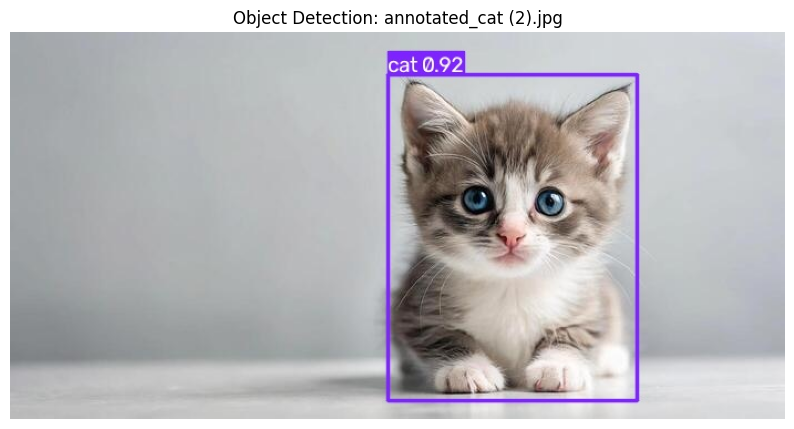

In [72]:
for filename in annotated_images:

    img = cv2.imread(filename)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.title("Object Detection: " + filename)
    plt.axis("off")
    plt.show()

**Analyze Uploaded Videos**

In [73]:
video_extensions = (".mp4", ".avi", ".mov", ".mkv")

for filename in uploaded.keys():

    if filename.lower().endswith(video_extensions):

        cap = cv2.VideoCapture(filename)

        if not cap.isOpened():
            print("Could not open video:", filename)
            continue

        fps = cap.get(cv2.CAP_PROP_FPS)

        if not fps or fps <= 0:
            fps = 25

        frame_interval = int(fps * 2)

        frame_number = 0
        analyzed_count = 0
        video_metadata = []

        while analyzed_count < 10:

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

            ret, frame = cap.read()

            if not ret:
                break

            frame_time = round(frame_number / fps, 2)

            metadata, objects, colors = analyze_image(
                frame,
                filename,
                "Video Frame",
                frame_time
            )

            all_metadata.append(metadata)
            video_metadata.append(metadata)

            analyzed_count += 1
            frame_number += frame_interval

        cap.release()

        print(
            "Video analyzed:",
            filename,
            "| Frames analyzed:",
            analyzed_count
        )

print("Video analysis completed!")

Video analysis completed!


**Display Final Metadata**

In [76]:
metadata_df = pd.DataFrame(all_metadata)

display(metadata_df)

print("Total assets/frames analyzed:", len(metadata_df))

,Asset_Name,Asset_Type,Frame_Time_Seconds,Objects_Detected,Object_Count,Dominant_Colors,Brightness,Lighting_Score,Contrast,Contrast_Score,Auto_Tags
0,cat (2).jpg,Image,None,cat,1,"#bec0c1, #4e443e, #a8a9aa, #d6d7d7, #8b817b",179.94,58.87,35.59,55.61,"cat, High-Brightness, Low-Contrast, Computer-V..."


Total assets/frames analyzed: 1


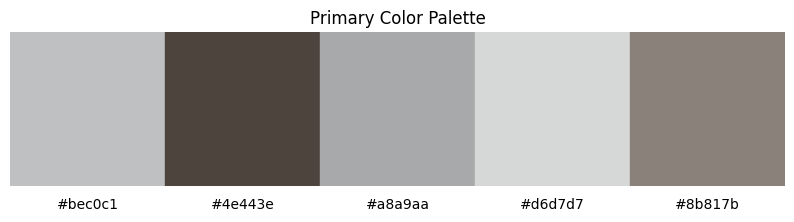

In [81]:
def show_color_palette(colors):

    fig, ax = plt.subplots(figsize=(10, 2))

    for i, color in enumerate(colors):
        ax.add_patch(
            plt.Rectangle((i, 0), 1, 1, color=color)
        )

        ax.text(
            i + 0.5, -0.15,
            color,
            ha="center"
        )

    ax.set_xlim(0, len(colors))
    ax.set_ylim(0, 1)
    ax.axis("off")

    plt.title("Primary Color Palette")
    plt.show()


if len(all_metadata) > 0:
    colors = all_metadata[0]["Dominant_Colors"].split(", ")
    show_color_palette(colors)

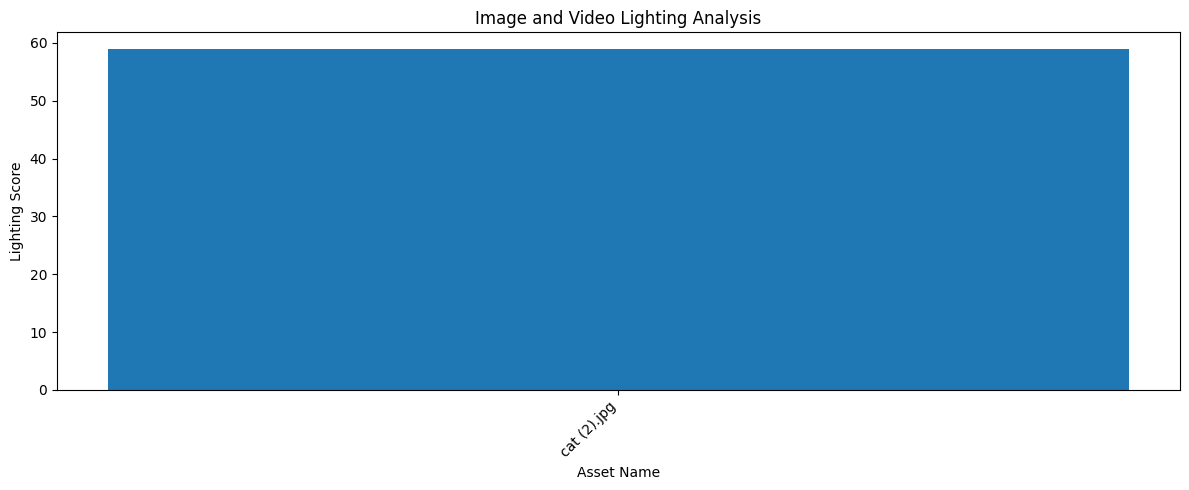

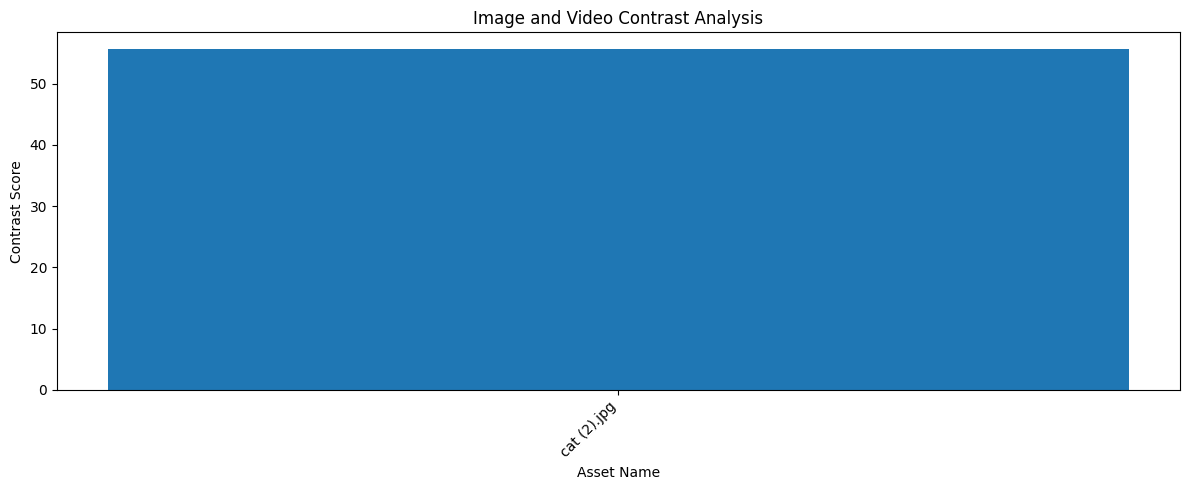

In [87]:
if not metadata_df.empty:

    plt.figure(figsize=(12, 5))

    plt.bar(
        metadata_df["Asset_Name"],
        metadata_df["Lighting_Score"]
    )

    plt.title("Image and Video Lighting Analysis")
    plt.xlabel("Asset Name")
    plt.ylabel("Lighting Score")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))

    plt.bar(
        metadata_df["Asset_Name"],
        metadata_df["Contrast_Score"]
    )

    plt.title("Image and Video Contrast Analysis")
    plt.xlabel("Asset Name")
    plt.ylabel("Contrast Score")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

**Visualize Object Detection Results**

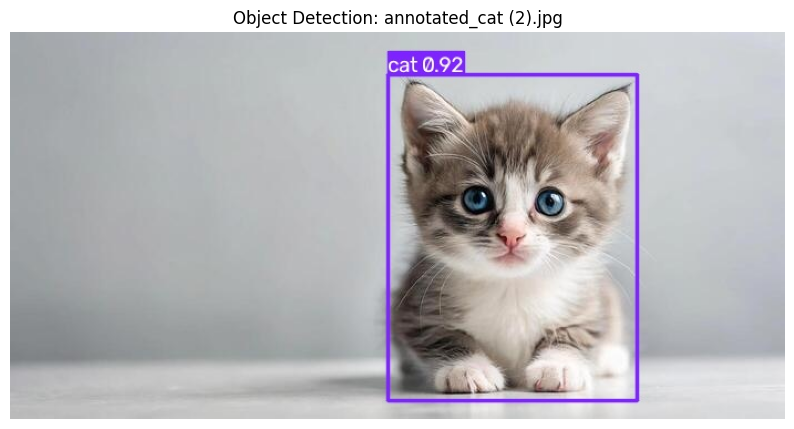

In [82]:
for filename in annotated_images:

    img = cv2.imread(filename)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.title("Object Detection: " + filename)
    plt.axis("off")
    plt.show()

**Visualize Dominant Color Palette**

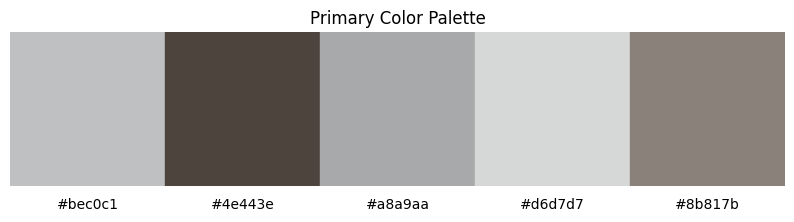

In [88]:
def show_color_palette(colors):

    fig, ax = plt.subplots(figsize=(10, 2))

    for i, color in enumerate(colors):
        ax.add_patch(
            plt.Rectangle(
                (i, 0), 1, 1,
                color=color
            )
        )
        ax.text(
            i + 0.5, -0.15,
            color,
            ha="center",
            fontsize=10
        )

    ax.set_xlim(0, len(colors))
    ax.set_ylim(0, 1)
    ax.axis("off")

    plt.title("Primary Color Palette")
    plt.show()


if len(all_metadata) > 0:
    first_colors = all_metadata[0]["Dominant_Colors"].split(", ")
    show_color_palette(first_colors)

**Generate Brightness and Contrast Reports**

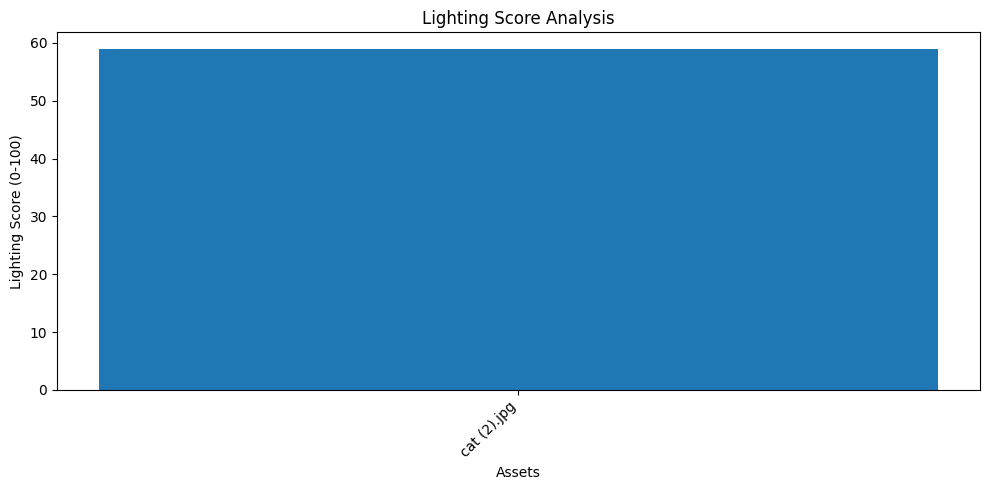

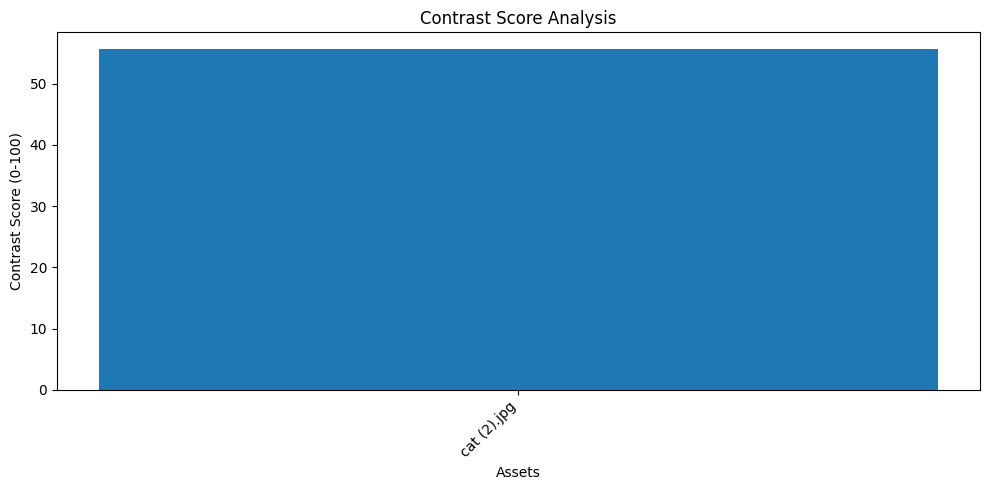

In [84]:
if not metadata_df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        metadata_df["Asset_Name"],
        metadata_df["Lighting_Score"]
    )

    plt.title("Lighting Score Analysis")
    plt.xlabel("Assets")
    plt.ylabel("Lighting Score (0-100)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(10, 5))

    plt.bar(
        metadata_df["Asset_Name"],
        metadata_df["Contrast_Score"]
    )

    plt.title("Contrast Score Analysis")
    plt.xlabel("Assets")
    plt.ylabel("Contrast Score (0-100)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

**Export Metadata to CSV and JSON**

In [91]:
if not metadata_df.empty:

    metadata_df.to_csv(
        "image_video_metadata.csv",
        index=False
    )

    metadata_df.to_json(
        "image_video_metadata.json",
        orient="records",
        indent=4
    )

    print("CSV report generated successfully!")
    print("JSON report generated successfully!")

    files.download("image_video_metadata.csv")
    files.download("image_video_metadata.json")

else:
    print("No assets available for export.")

CSV report generated successfully!
JSON report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Download Annotated Images**

In [92]:
import zipfile

with zipfile.ZipFile(
    "annotated_images.zip",
    "w"
) as zipf:

    for filename in annotated_images:
        zipf.write(filename)

if annotated_images:
    files.download("annotated_images.zip")
else:
    print("No annotated images available.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>